*This notebook was developed by Kabelo Tsiane for the DESC CL_Cosmo_Pipeline team.*

# Running the TXPipe cluster lensing pipeline on DP2

This notebook shows how to run the TXPipe cluster lensing pipeline on Rubin Data Preview 2, and presents its outputs: stacked $\Delta\Sigma$ and reduced tangential shear ($g_t$) profiles around clusters.

It is meant to be run independently. You must run the pipelines from the terminal first; see Section 1. The companion notebook `dp2_shear_catalog_comparison.ipynb` explains the three shear catalogs that feed the pipeline.

___

## The DP2 setup at a glance

The work is split into three ceci pipelines, each in its own directory under `~/txp/dp2/`:

| pipeline | what it does | depends on |
|---|---|---|
| `common/` | cuts the shear catalog to the mask, selects and calibrates sources, BPZ photo-z for every source, bins the clusters in redshift and richness, source and PSF maps | the inputs below |
| `delta_sigma/` | cluster-source pairs and stacked $\Delta\Sigma(R)$ profiles in Mpc | outputs of `common/` |
| `gt/` | the same two stages with `delta_sigma: false`: stacked $g_t(\theta)$ in arcmin | outputs of `common/` |

Each pipeline directory holds one pipeline file per shear catalog (`pipeline_rubin.yml`, `pipeline_sheldon.yml`) and one `config.yml` shared by all catalogs, so the BPZ, cluster binning and profile settings are identical between catalogs. Outputs go to `/pscratch/sd/k/kabelo/dp2/outputs/<catalog>/`, with the profiles in its `delta_sigma/` and `gt/` sub-directories (the two run the same stages with the same output names).

**Shear catalogs and masks.** Each catalog comes from the DESC data registry and is cut with the mask the DESC DP2 mask page assigns to its shape method (wide field only):

| catalog | registry catalog | registry mask | status |
|---|---|---|---|
| Rubin metaDetect | 137 `txpipe_dp2_shear_catalog_Rubin_metaDetect` 0.3.0 | 151 `rubin_dp2_wide_metadetect_mask` 0.2.0 | run 2026-10-12 (`*/pipeline_rubin.yml`). The earlier run with the older mask 138 (= `rubin_dp2_shear_mask` 0.1.0), whose profiles also used the wrong shear convention (Section 5.1), is kept in `outputs/rubin_mask138/` |
| Sheldon metadetect | 147 `txpipe_dp2_shear_catalog_desc_metaDetect_masked` 0.1.0 (already cut to Erin's footprint, 148) | 151 | run 2026-10-12 (`*/pipeline_sheldon.yml`) |
| AnaCal | 161 `txpipe_dp2_shear_catalog_anacal_full` 0.1.1 | 152 `rubin_dp2_wide_anacal_mask` 0.2.0 | waiting: TXPipe's AnaCal branch is not yet compatible with the metadetect code we use |

The masks are applied by TXPipe's own stages: `TXIngestHealsparseMask` rewrites the registry `.hsp` map as a TXPipe mask file, and `TXCutShearCatalog` keeps the objects inside it. For Sheldon, catalog 147 is already cut to Erin's footprint, so cutting it again with 151 keeps the sky inside both.

**TXPipe version.** The runs of 12 Oct 2026 used the TXPipe branch `Metadetect_aliasing` (J. Zuntz's DP2 branch, commit `2b121807`), which provides the DP2 Rubin selector, the g1-only ("scalar") metadetect calibration and the selector with Erin Sheldon's cuts. That branch has since been merged into `cl_tutorials`, which has the same pipeline code plus the `CLIngestClusterCSV` stage used by the one-step tutorial pipelines in TXPipe's `examples/dp2/Cluster_pipelines/` (see `Run_CL_dp2_pipeline.ipynb`). The submit scripts print the branch and commit at the top of each SLURM log.

The cluster catalog, the fiducial cosmology and the cluster binning are the same for every shear catalog.

In [1]:
import os
import pickle

import ceci
import h5py

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import yaml
from IPython.display import Image

Make sure to change the paths in the next cell to your own TXPipe and DP2 directories, and pick the shear catalog to look at.

In [2]:
# user specific paths -- NERSC example
my_txpipe_dir = "/global/cfs/cdirs/m1727/kabelo/TXPipe"
my_dp2_dir = "/global/u2/k/kabelo/CL_JKcovariance_testing/dp2"

# Output directory of each run (one per shear catalog). The profiles are in its delta_sigma/ and gt/ sub-directories.
OUTPUTS = {
    "rubin_mask138": "/pscratch/sd/k/kabelo/dp2/outputs/rubin_mask138",  # Rubin, older mask 138 (Sep 2026)
    "rubin": "/pscratch/sd/k/kabelo/dp2/outputs/rubin",                  # Rubin, mask 151
    "sheldon": "/pscratch/sd/k/kabelo/dp2/outputs/sheldon",              # Sheldon, 148 & 151
}
print("finished runs:", [k for k, v in OUTPUTS.items() if os.path.exists(f"{v}/gt/cluster_profiles.pkl")])

CATALOG = "rubin"              # which run's outputs to look at in Section 4
PIPELINE_CATALOG = "rubin"     # which catalog's pipeline files to show in Sections 2 and 3

PIPELINES = ["common", "delta_sigma", "gt"]
out_dir = OUTPUTS[CATALOG]

# TXPipe is used from its source directory, not installed
import sys
sys.path.insert(0, my_txpipe_dir)
import txpipe

finished runs: ['rubin_mask138', 'rubin', 'sheldon']


___

# 1 - Launching the pipelines

Each pipeline has a submission script in its directory, which takes the shear catalog as its argument. They need a compute node, not a login node (`site: nersc-interactive` launches the stages with `srun`). Run `common` first, then `delta_sigma` and `gt`, which only read its outputs.

### **On NERSC, from `~/txp/dp2`, run:**
```
./submit_dp2_chain.sh rubin          # or: sheldon
```
This submits `common`, then `delta_sigma` and `gt` with `--dependency=afterok`, which holds the profile jobs until `common` finishes successfully. If `common` has already run, use `./submit_dp2_chain.sh rubin --skip-common` to submit only the profiles. The individual scripts can also be submitted by hand, e.g. `sbatch -J dp2_common_rubin common/submit_dp2_common.sh rubin`.

All three pipelines use `resume: true`, so a re-run skips the stages whose outputs already exist. Delete an output to force its stage to run again.

### **How long does it take?**

Times from the Rubin run from scratch (Sep 2026, 1 CPU node, 64 MPI tasks; SLURM job 58961576 and the stage logs):

| pipeline | stage | time |
|---|---|---|
| `common` | `TXCutShearCatalog` | 5 min 37 s |
| | `TXSourceSelectorMetadetectDP2` | 1 min 55 s |
| | `BPZliteEstimator` | 17 min 23 s |
| | `TXShearCalibration` | 1 min 26 s |
| | `TXSourceMaps`, `TXJackknifeCentersSource`, `TXSourceTomography`, `TXPSFMaps`, `BPZliteInformer`, `CLClusterBinningRedshiftRichness` | < 1 min each, ~3 min together |
| | **total** | **~30 min** |
| `delta_sigma` | `CLClusterShearCatalogs` + `CLClusterEnsembleProfiles` | 4 min 51 s + 0.3 min, **~5 min** |
| `gt` | `CLClusterShearCatalogs` + `CLClusterEnsembleProfiles` | 4.3 min + 0.4 min, **~5 min** |

So about 35 min of compute from `common` to the $\Delta\Sigma$ profiles, with `gt` running alongside `delta_sigma`. The wait in the queue is usually longer: our `regular` QOS jobs waited 1¼–1¾ hours to start (Sep 2026), so plan on ~2–2½ hours from submission to profiles.

`TXCutShearCatalog` and `BPZliteEstimator` scale with the number of rows in the shear catalog (BPZ runs on every row, not only the sources). The Sheldon catalog (registry 147) has ~2.8× as many rows as Rubin's cut catalog, so expect its `common` run to take roughly twice as long.

The SLURM log of each job is written to `/pscratch/sd/k/kabelo/dp2/outputs/slurm-<jobname>-<jobid>.out`, and each stage's own log to `outputs/<catalog>/logs/` (or `.../delta_sigma/logs/`, `.../gt/logs/`). If you see *'Pipeline successful.  Joy is sparked.'*: congratulations, it worked!

Once the pipelines have run you can go directly to Section 4 to look at the results.

___

# 2 - Looking at the different pipeline files

### **Let's look at the submission script of the `common` pipeline:**

In [3]:
! cat {my_dp2_dir}/common/submit_dp2_common.sh

#!/bin/bash
#SBATCH -A m1727
#SBATCH -C cpu
#SBATCH -q regular
#SBATCH -N 1
#SBATCH --ntasks-per-node=64
#SBATCH --cpus-per-task=2
#SBATCH --time=00:15:00
#SBATCH --job-name=dp2_common
#SBATCH --output=/pscratch/sd/k/kabelo/dp2/outputs/slurm-%x-%j.out
#SBATCH --mail-user=kabelo@umich.edu
#SBATCH --mail-type=BEGIN,END,FAIL
#
# Usage, from ~/txp/dp2:   sbatch -J dp2_common_<catalog> common/submit_dp2_common.sh <catalog>
#   <catalog> = rubin | sheldon   (runs common/pipeline_<catalog>.yml)
#
# Time limit: the Rubin run from scratch took ~35 min (Sep 2026), dominated by
# BPZliteEstimator (~17 min). The Sheldon catalog has ~2.8x as many rows, and
# TXCutShearCatalog and BPZliteEstimator scale with rows, so allow ~2.5 h.
# resume: true skips finished stages on reruns.

set -e
CATALOG=${1:?usage: sbatch common/submit_dp2_common.sh <rubin|sheldon>}
cd /global/u2/k/kabelo/CL_JKcovariance_testing/dp2/common
PIPELINE=pipeline_${CATALOG}.yml
[ -f "$PIPELINE" ] || { echo "No $PIPELINE in $(pwd)";

The three submissions for one catalog are chained by `submit_dp2_chain.sh`:

In [4]:
! cat {my_dp2_dir}/submit_dp2_chain.sh

#!/bin/bash
# Submit the full DP2 cluster-lensing chain for one shear catalog:
#   common  ->  delta_sigma and gt (in parallel, each only if common succeeds)
#
# Usage, from ~/txp/dp2:   ./submit_dp2_chain.sh <catalog> [--skip-common]
#   <catalog> = rubin | sheldon
#   --skip-common: common has already run; submit only the two profile pipelines
#
# SLURM logs: /pscratch/sd/k/kabelo/dp2/outputs/slurm-<jobname>-<jobid>.out

set -e
CATALOG=${1:?usage: ./submit_dp2_chain.sh <rubin|sheldon> [--skip-common]}
cd "$(dirname "$0")"
for d in common delta_sigma gt; do
    [ -f "$d/pipeline_${CATALOG}.yml" ] || { echo "No $d/pipeline_${CATALOG}.yml"; exit 1; }
done

if [ "$2" == "--skip-common" ]; then
    DEP=""
else
    jid=$(sbatch --parsable -J dp2_common_${CATALOG} common/submit_dp2_common.sh ${CATALOG})
    echo "common:      job $jid"
    DEP="--dependency=afterok:$jid"
fi
echo "delta_sigma: job $(sbatch --parsable $DEP -J dp2_delta_sigma_${CATALOG} delta_sigma/submit_dp2_delta_sigma.sh ${

### **The submission script runs `ceci` on the pipeline yaml file. Let's look at it:**

- `site` and `launcher` say where and how the stages run.
- `stages` lists the stages in the pipeline. `aliases` rename a stage's input or output tags so that stages fit together: `TXCutShearCatalog` reads the registry catalog as `full_shear_catalog` and writes the cut catalog that everything else reads as `shear_catalog`.
- `inputs` with an `id:` are looked up in the DESC data registry (this needs the `registry:` block).

In [5]:
! cat {my_dp2_dir}/common/pipeline_{PIPELINE_CATALOG}.yml

# Shared DP2 stages for the RUBIN metadetect shear catalog: everything that
# doesn't depend on the profile type. Outputs land in
# /pscratch/sd/k/kabelo/dp2/outputs/rubin/ and are read as inputs by
# ../delta_sigma and ../gt, which write their own outputs to
# outputs/rubin/delta_sigma/ and outputs/rubin/gt/. Run this first.
#
# Settings shared by every shear catalog live in ./config.yml; see
# pipeline_sheldon.yml for the Sheldon catalog.

site:
    # Cray/Perlmutter has no mpirun -- NerscSite launches via srun instead,
    # and reads real node/cpu counts from SLURM_JOB_NODELIST/SLURM_CPUS_ON_NODE
    # rather than psutil, so max_processes/max_threads (LocalSite-only
    # concepts) aren't needed here.
    name: nersc-interactive

launcher:
    name: mini
    interval: 1.0

modules: >
    txpipe
    rail.estimation.algos.bpz_lite
    txpipe.extensions.cluster_counts.bin_cluster

python_paths:
    - /global/cfs/cdirs/m1727/kabelo/TXPipe

stages:
  - name: TXIngestHealsparseMask   # r

### **What differs between shear catalogs?** Only the input catalog, the source selector (and its calibration), and the outputs. Sheldon's pipeline also leaves out `TXPSFMaps`, as that catalog has no `psf_g1`/`psf_g2` columns.

In [6]:
! diff {my_dp2_dir}/common/pipeline_rubin.yml {my_dp2_dir}/common/pipeline_sheldon.yml

1,5c1,4
< # Shared DP2 stages for the RUBIN metadetect shear catalog: everything that
< # doesn't depend on the profile type. Outputs land in
< # /pscratch/sd/k/kabelo/dp2/outputs/rubin/ and are read as inputs by
< # ../delta_sigma and ../gt, which write their own outputs to
< # outputs/rubin/delta_sigma/ and outputs/rubin/gt/. Run this first.
---
> # Shared DP2 stages for the SHELDON (DESC) metadetect shear catalog:
> # everything that doesn't depend on the profile type. Outputs land in
> # /pscratch/sd/k/kabelo/dp2/outputs/sheldon/ and are read as inputs by
> # ../delta_sigma and ../gt. Run this first.
7,8c6,12
< # Settings shared by every shear catalog live in ./config.yml; see
< # pipeline_sheldon.yml for the Sheldon catalog.
---
> # Differences from pipeline_rubin.yml:
> #  - the catalog has only the ns/1p/1m (g1) shear steps, so TXPipe treats it as
> #    "scalar_metadetect" and calibrates with R = R11 for both components;
> #  - the source selector applies E. Sheldon's cuts (TXS

### **Each stage reads its options from the config file, shared by all catalogs.** Each catalog's source selector has its own section: `TXSourceSelectorMetadetectDP2` (Rubin) and `TXSourceSelectorScalarMetadetectDP2` (Sheldon, Erin's Table 7 cuts).

In [7]:
! cat {my_dp2_dir}/common/config.yml

# Shared-stage config for DP2 (source selection, BPZ, cluster binning), used by
# pipeline_rubin.yml and pipeline_sheldon.yml. Settings that must match between
# shear catalogs for a fair comparison (BPZ, cluster binning, nside) are kept in
# one place; each catalog's source selector has its own section.
# Profile-specific settings live in ../delta_sigma and ../gt. This is all a
# rough start, some copied configs so not fully tuned.

global:
    nside: 64
    chunk_rows: 1000000

TXIngestHealsparseMask: {}   # no options: reads the registry .hsp and rewrites it as a TXPipe mask file

TXSourceTomography:
    bands: [r, i, z] #used for selection
    source_zbin_edges: [0.1, 3.0] # this can be big, not doing cosmic shear

TXSourceSelectorMetadetectDP2:
    input_pz: false
    bands: [g, r, i, z] # the selector takes the bands from the catalog file
    T_cut: 0.5
    s2n_cut: 10.0
    delta_gamma: 0.02
    source_zbin_edges: [0.1, 3.0]
    true_z: false
    do_tomography: false
    # DP2 c

### **The profile pipelines**

`delta_sigma/` and `gt/` run `CLClusterShearCatalogs` and `CLClusterEnsembleProfiles`, reading the `common` outputs as inputs. Their configs differ only in the profile type and the radial binning: $\Delta\Sigma$ in 6 log bins over 0.2–4.5 Mpc (sources within 5 Mpc), and $g_t$ in 6 log bins over 1–20 arcmin (sources within 22 arcmin).

In [8]:
! cat {my_dp2_dir}/delta_sigma/pipeline_{PIPELINE_CATALOG}.yml

# Delta-sigma cluster profiles for DP2: RUBIN shear catalog.
#
# Only the delta_sigma-specific stages run here. Everything upstream (cut shear
# catalogue, source selection/tomography, BPZ p(z), cluster binning) is
# shared with the gt pipeline and read from
# /pscratch/sd/k/kabelo/dp2/outputs/rubin/ via `inputs` below, so run
# ../common/pipeline_rubin.yml first if those are missing. Outputs and stage logs go
# under outputs/rubin/delta_sigma/ so they don't clash with the gt ones (same
# stage names, same output tags).

site:
    name: nersc-interactive

launcher:
    name: mini
    interval: 1.0

modules: >
    txpipe
    txpipe.extensions.cluster_counts.sources_select_compute
    txpipe.extensions.cluster_counts.make_ensemble_profile

python_paths:
    - /global/cfs/cdirs/m1727/kabelo/TXPipe

stages:
  - name: CLClusterShearCatalogs
    classname: CLClusterShearCatalogs
    nprocess: 1

  - name: CLClusterEnsembleProfiles
    classname: CLClusterEnsembleProfiles
    nprocess: 1

out

In [9]:
! diff {my_dp2_dir}/delta_sigma/config.yml {my_dp2_dir}/gt/config.yml

1,2c1,2
< # delta_sigma version; see ../gt/config.yml for the reduced-shear one. Only the
< # cluster profile stages run in this pipeline; the upstream settings live in
---
> # gt (reduced shear) version of ../delta_sigma/config.yml. Only the cluster
> # stages run in this pipeline; the upstream settings live in
12,13c12,17
<     use_radius: true
<     max_radius: 5.0                 # Mpc
---
>     # Profiles are binned in arcmin, so select sources within a fixed angle
>     # for every cluster rather than a fixed physical radius (use_radius: true
>     # would give each cluster its own theta_max = max_radius / D_A(z), leaving
>     # the outer arcmin bins incomplete for high-z clusters).
>     use_radius: false
>     max_angle: 22.0                 # arcmin; margin above r_max=20
25c29
<     delta_sigma: true
---
>     delta_sigma: false              # tangential/cross reduced shear; sigma_crit not applied
29,30c33,36
<     r_min: 0.2
<     r_max: 4.5                      # Mpc; marg

___

# 3 - Producing and looking at the pipeline diagrams

Here we run each pipeline in "dry-run" mode, to check that it can run and to produce a diagram of it as a png. Each pipeline file uses paths relative to its own directory, so we run from there.

In [10]:
flowcharts = {}
for name in PIPELINES:
    os.chdir(f"{my_dp2_dir}/{name}")
    flowcharts[name] = f"{my_dp2_dir}/{name}/{name}_pipeline_{PIPELINE_CATALOG}.png"
    pipeline_config = ceci.Pipeline.build_config(f"pipeline_{PIPELINE_CATALOG}.yml", flow_chart=flowcharts[name], dry_run=True)
    ceci.run_pipeline(pipeline_config);
os.chdir(my_dp2_dir)

In the diagrams, the red ellipses are stages, the yellow boxes are the pipeline's input files, and the blue boxes are the files it produces.

### **The `common` pipeline**

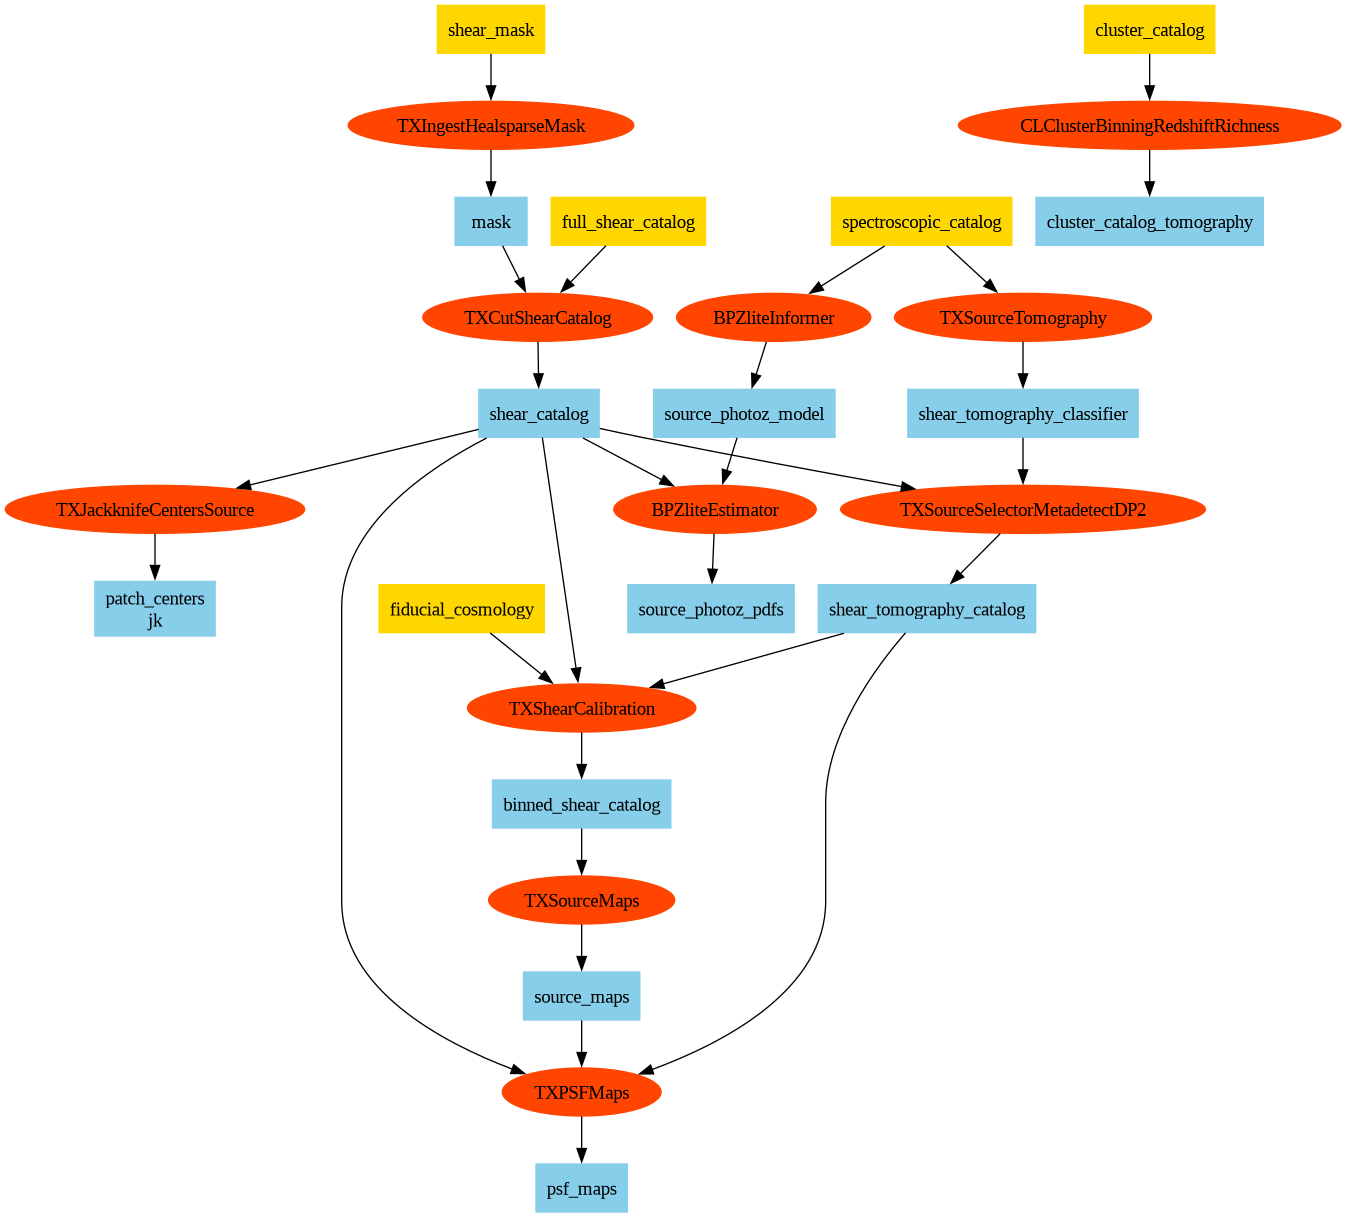

In [11]:
Image(flowcharts["common"])

### **The profile pipelines** (`delta_sigma/` and `gt/` have the same diagram)

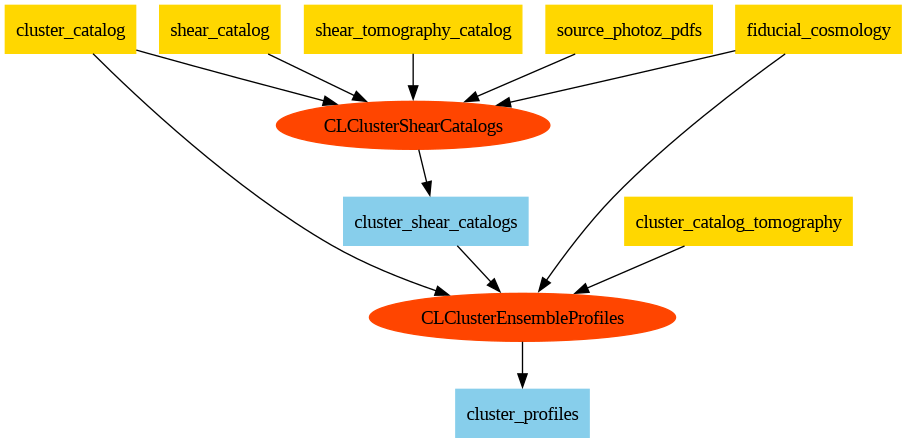

In [12]:
Image(flowcharts["delta_sigma"])

___

# 4 - Opening and looking at the outputs

## 4.1 The source sample (`common`)

`TXSourceSelectorMetadetectDP2` decides which objects are sources, and writes the selection and the calibration to `shear_tomography_catalog.hdf5`. We use a single source bin (`zmin`–`zmax`); the cluster stages then pick, for each cluster, the sources behind it.

- `tomography/bin` is −1 for rejected objects and 0 for sources. For metadetect, `bin_1p`, `bin_1m`, … hold the same selection applied to each sheared copy.
- `response/R_2d` is the response of the selected sample, selection response included: the 2×2 matrix for Rubin, a single number $R_{11}$ (used for both components) for Sheldon. The cluster stages divide the shears by it.
- `counts` holds the number of sources, the effective number $N_{\rm eff}$, the shape noise $\sigma_e$ and the mean (uncalibrated) ellipticity.

In [13]:
with h5py.File(f"{out_dir}/shear_tomography_catalog.hdf5") as f:
    print("catalog type:", f["tomography"].attrs["catalog_type"])
    print(f"source redshift range: {f['tomography'].attrs['zmin_0']} - {f['tomography'].attrs['zmax_0']}")
    print(f"sources: {f['counts/counts_2d'][0]:,}   N_eff: {f['counts/N_eff_2d'][0]:,.0f}   sigma_e: {f['counts/sigma_e_2d'][0]:.3f}")
    print(f"mean e1, e2 (before calibration): {f['counts/mean_e1_2d'][0]:+.5f}, {f['counts/mean_e2_2d'][0]:+.5f}")
    R = f["response/R_2d"][:]
    if R.size == 1:                       # g1-only (scalar) metadetect: R = R11 for both components
        R = R.item() * np.eye(2)
    mean_e = np.array([f["counts/mean_e1_2d"][0], f["counts/mean_e2_2d"][0]])
print("R =\n", R)
print("mean shear after calibration, R^-1 <e>:", np.linalg.solve(R, mean_e))

catalog type: metadetect
source redshift range: 0.0 - 999.0
sources: 23,531,745   N_eff: 23,149,666   sigma_e: 0.363
mean e1, e2 (before calibration): +0.00005, +0.00038
R =
 [[ 0.74651337 -0.00092279]
 [-0.00091642  0.749973  ]]
mean shear after calibration, R^-1 <e>: [7.2425755e-05 5.0398178e-04]


### **Source redshifts**

`BPZliteEstimator` computes a p(z) for every object in the cut shear catalog, not only for the sources, and stores its mode as `ancil/zmode`. `CLClusterShearCatalogs` uses `zmode` both to keep only sources behind each cluster (`redshift_cut_criterion: zmode`, with `delta_z: 0.2`) and to weight them. Here are the `zmode` distribution of the selected sources and their mean p(z). Reading every p(z) would mean ~60 GB, so the mean p(z) uses a sample: the first 100k rows of each 10M-row chunk.

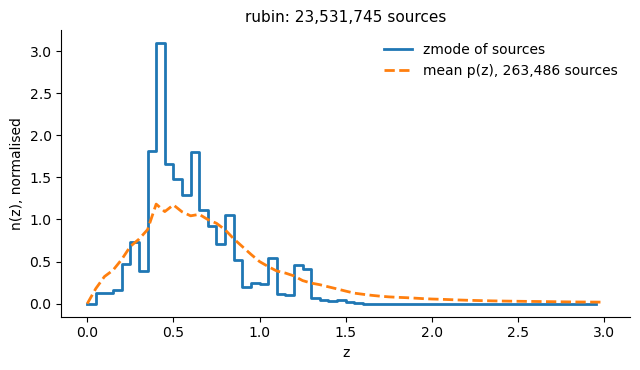

In [14]:
zbins = np.linspace(0, 3, 61)
hist = np.zeros(len(zbins) - 1)
pdf_sum, n_pdf = 0, 0
with h5py.File(f"{out_dir}/shear_tomography_catalog.hdf5") as t, h5py.File(f"{out_dir}/source_photoz_pdfs.hdf5") as pz:
    nrow = len(t["tomography/bin"])
    zgrid = pz["meta/xvals"][0]
    chunk = 10_000_000
    for s in range(0, nrow, chunk):
        sel = t["tomography/bin"][s:s + chunk] >= 0
        hist += np.histogram(pz["ancil/zmode"][s:s + chunk][sel], zbins)[0]
        # mean p(z) from the first 100k rows of each chunk (reading every p(z) means ~60 GB)
        sub = sel[:100_000]
        pdf_sum = pdf_sum + pz["data/yvals"][s:s + 100_000][sub].sum(axis=0)
        n_pdf += sub.sum()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.step(zbins[:-1], hist / hist.sum() / np.diff(zbins), where="post", lw=2, label="zmode of sources")
ax.plot(zgrid, pdf_sum / n_pdf / np.trapezoid(pdf_sum / n_pdf, zgrid), lw=2, ls="--", label=f"mean p(z), {n_pdf:,} sources")
ax.set_xlabel("z"); ax.set_ylabel("n(z), normalised")
ax.set_title(f"{CATALOG}: {hist.sum():,.0f} sources", fontsize=11)
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

## 4.2 The cluster bins (`common`)

`CLClusterBinningRedshiftRichness` splits the cluster catalog into redshift and richness bins, written to `cluster_catalog_tomography.hdf5` under `cluster_bin/bin_zbin_<i>_richbin_<j>`.

In [15]:
with h5py.File(f"{out_dir}/cluster_catalog_tomography.hdf5") as f:
    for b, g in f["cluster_bin"].items():
        z, lam = g["redshift"][:], g["richness"][:]
        rng = f"z {z.min():.2f}-{z.max():.2f}, richness {lam.min():.0f}-{lam.max():.0f}" if len(z) else ""
        print(f"{b}: {len(z):5d} clusters  {rng}")

bin_zbin_0_richbin_0:   158 clusters  z 0.20-0.35, richness 20-24
bin_zbin_0_richbin_1:   181 clusters  z 0.20-0.35, richness 24-32
bin_zbin_0_richbin_2:   196 clusters  z 0.20-0.35, richness 32-164
bin_zbin_1_richbin_0:   349 clusters  z 0.35-0.50, richness 20-24
bin_zbin_1_richbin_1:   315 clusters  z 0.35-0.50, richness 24-32
bin_zbin_1_richbin_2:   363 clusters  z 0.35-0.50, richness 32-178
bin_zbin_2_richbin_0:   378 clusters  z 0.50-0.78, richness 20-24
bin_zbin_2_richbin_1:   393 clusters  z 0.50-0.78, richness 24-32
bin_zbin_2_richbin_2:   301 clusters  z 0.50-0.75, richness 32-137


## 4.3 The stacked profiles (`delta_sigma` and `gt`)

### **Open the profile outputs of the chosen run**

In [16]:
profiles = {}
for name in ["delta_sigma", "gt"]:
    # the output_dir of {name}/pipeline_<catalog>.yml
    profiles[name] = pickle.load(open(f"{out_dir}/{name}/cluster_profiles.pkl", "rb"))
list(profiles["delta_sigma"])

['bin_zbin_0_richbin_0',
 'bin_zbin_0_richbin_1',
 'bin_zbin_0_richbin_2',
 'bin_zbin_1_richbin_0',
 'bin_zbin_1_richbin_1',
 'bin_zbin_1_richbin_2',
 'bin_zbin_2_richbin_0',
 'bin_zbin_2_richbin_1',
 'bin_zbin_2_richbin_2']

The output is a dictionary with one entry per redshift/richness bin, each holding a `CLMM` `ClusterEnsemble` object (or `None` when the bin has no clusters).

### **Exploring the output**

In [17]:
example_bin = "bin_zbin_0_richbin_1"
data = profiles["delta_sigma"]
#This is the info for this bin
{k: v for k, v in data[example_bin].items()}

{'cluster_bin_edges': {'rich_max': np.float64(32.0),
  'rich_min': np.float64(24.0),
  'z_max': np.float64(0.35),
  'z_min': np.float64(0.2)},
 'n_cl': 181,
 'clmm_cluster_ensemble': <clmm.clusterensemble.ClusterEnsemble at 0x7f9fca56dd10>,
 'profile_type': 'delta_sigma',
 'jackknife_regions': 'kmeans',
 'jackknife_centers': array([[ 3.39588054e+02,  1.62291367e+00],
        [ 3.49711142e+02, -1.60345300e+00],
        [ 7.15299173e+00, -2.54715920e+00],
        [ 6.17515036e-01, -6.01071554e+00],
        [ 3.46434386e+02, -1.56388676e+00],
        [ 4.17932884e-01, -1.83974907e+00],
        [ 3.59216997e+00,  3.73452543e+00],
        [ 6.08348616e-01, -3.78657167e+00],
        [ 9.48609270e-01,  2.12927959e-01],
        [ 3.34883259e+02, -9.71605500e-01],
        [ 3.54088047e+02,  7.74689376e-01],
        [ 3.55924151e+02,  6.55899711e-01],
        [ 8.31751996e+00,  8.27830665e-01],
        [ 3.57110417e+02, -1.15237473e+00],
        [ 3.30469793e+02, -1.51474155e+00],
        [ 2.90

In [18]:
#This shows the table with all clusters in this bin and their individual profiles
data[example_bin]["clmm_cluster_ensemble"].data

cluster_id,ra,dec,z,radius,tangential_comp,cross_comp,W_l
str5,float64,float64,float64,float64[6],float64[6],float64[6],float64[6]
8497,6.67898072024882,-6.10253100495023,0.2348720729351043,nan .. 3.825915869051223,nan .. 243456401947573.44,nan .. 13909426648261.57,0.0 .. 2.7549852981766047e-30
8676,4.25336216136077,-4.88640878397068,0.2743885815143585,0.29519405387704917 .. 3.7603561075267478,-586782880985034.2 .. 83469125661910.27,-1657222893233579.0 .. -34952577341041.707,1.0040735445508637e-31 .. 5.244707980068872e-29
8275,357.191979869141,-2.40111293595387,0.2342176437377929,0.25952413204799585 .. 3.6922408703821583,241100482969288.9 .. 19626252006023.58,-230825659372646.5 .. -33737519226833.3,5.822696102793931e-31 .. 2.733981726183754e-28
12699,359.832153260702,-3.14457608256585,0.3060041069984436,0.24888365808525642 .. 3.5068328665373927,-188920312699218.8 .. 85469057886440.95,388383884346760.4 .. 50984100088784.14,2.635534366843843e-31 .. 1.8790074604855576e-29
21357,8.97942676133144,-2.98042040814717,0.3211315274238586,0.29011934817045865 .. 3.663002525144197,2227108730469080.8 .. -120950476700613.7,-423451033319026.94 .. -78215183568191.7,1.226623529608325e-31 .. 1.8309893540625217e-29
6870,6.49465981729213,-3.31178364236063,0.2182098925113678,0.2873475255197595 .. 3.406004309570252,343065502566810.5 .. 56396867037195.97,-137798311398397.75 .. -2111512163704.933,6.251614285533796e-31 .. 4.423938566785588e-29
14196,5.66754975278354,-2.63957031512749,0.3450728058815002,0.30804758208293403 .. 3.748890327277563,-2073167649044463.0 .. 336552515731598.3,-1367185521666605.5 .. 109525867300150.12,8.578295995484826e-32 .. 2.5204092564739598e-30
30264,7.186962258309,-3.38426928007767,0.212726354598999,nan .. 3.861754245816345,nan .. 10539208603603.512,nan .. 64868648230236.4,0.0 .. 6.524299694472389e-29
5655,7.61217544522661,-0.942828742967148,0.2241547256708145,nan .. 3.5554252926205048,nan .. -7878611959610.105,nan .. 290776035254606.9,0.0 .. 4.221386733607283e-30


In [19]:
#This shows the stacked profile
data[example_bin]["clmm_cluster_ensemble"].stacked_data

radius_min,radius_max,radius,tangential_comp,cross_comp
float64,float64,float64,float64,float64
0.20000000000000004,0.33604214537126653,0.27256801464017266,41217601878289.73,-13836336227358.885
0.33604214537126653,0.5646216173286172,0.4633041309279817,151153702160072.66,-24249248426769.027
0.5646216173286172,0.9486832980505139,0.7844865237566153,58275519964632.08,-12016648879494.107
0.9486832980505139,1.5939878537739167,1.2984761594645262,20658399813031.43,1776002929540.2646
1.5939878537739167,2.6782354903896386,2.2312214042890366,13628007276383.006,2000816042280.8064
2.6782354903896386,4.500000000000001,3.689769133214986,19255925950543.723,-5611097256590.401


In [20]:
#The covariance of the stacked profile: here jackknife ('tan_jk', 'cross_jk') over healpix regions
{k: (None if v is None else v.shape) for k, v in data[example_bin]["clmm_cluster_ensemble"].cov.items()}

{'tan_sc': None,
 'cross_sc': None,
 'tan_bs': None,
 'cross_bs': None,
 'tan_jk': (6, 6),
 'cross_jk': (6, 6)}

### **Plot the profiles**

Each panel is one redshift/richness bin (empty bins are left out). Filled points are the tangential component, open points the cross component, which should be consistent with zero. Error bars are the square root of the jackknife covariance diagonal.

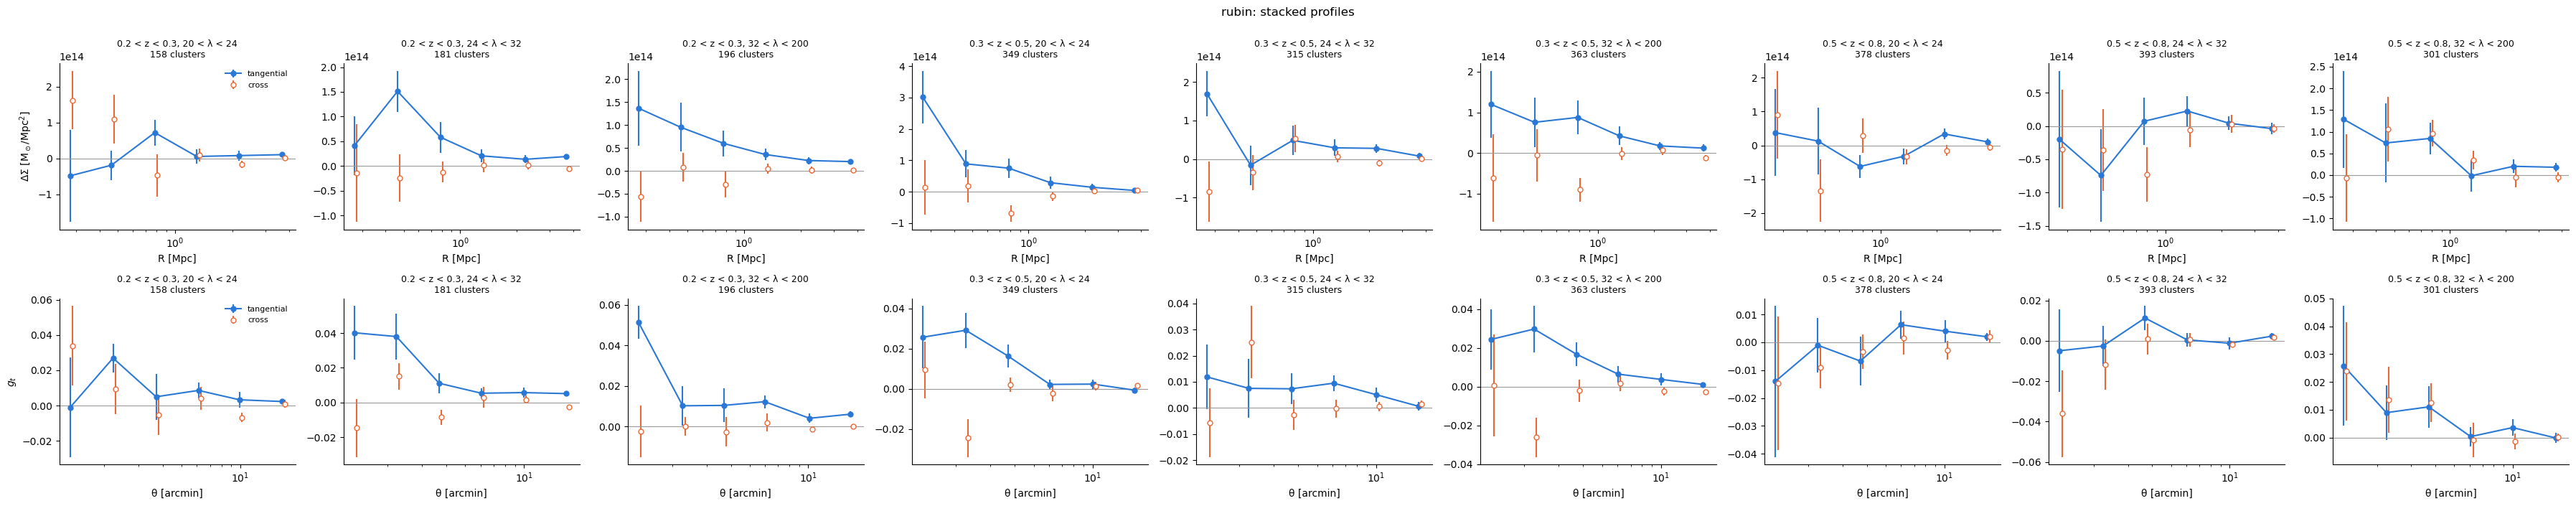

In [21]:
def plot_profiles(prof, kind, ax_row):
    bins = [b for b, e in prof.items() if e["n_cl"] > 0]
    for ax, b in zip(ax_row, bins):
        e = prof[b]
        ens = e["clmm_cluster_ensemble"]
        r, tan, cross = (ens.stacked_data[c] for c in ("radius", "tangential_comp", "cross_comp"))
        ax.errorbar(r, tan, yerr=np.sqrt(np.diag(ens.cov["tan_jk"])), fmt="o-", color="#2a78d6", ms=5, lw=1.5, label="tangential")
        ax.errorbar(r * 1.03, cross, yerr=np.sqrt(np.diag(ens.cov["cross_jk"])), fmt="o", mfc="white", color="#eb6834", ms=5, lw=1.5, label="cross")
        ax.axhline(0, color="0.6", lw=0.8)
        ax.set_xscale("log")
        edges = e["cluster_bin_edges"]
        ax.set_title(f"{edges['z_min']:.1f} < z < {edges['z_max']:.1f}, {edges['rich_min']:.0f} < λ < {edges['rich_max']:.0f}\n{e['n_cl']} clusters", fontsize=9)
        ax.set_xlabel("R [Mpc]" if kind == "delta_sigma" else "θ [arcmin]")
        ax.spines[["top", "right"]].set_visible(False)
    ax_row[0].set_ylabel(r"$\Delta\Sigma$ [M$_\odot$/Mpc$^2$]" if kind == "delta_sigma" else r"$g_t$")
    ax_row[0].legend(frameon=False, fontsize=8)

nbin = max(sum(e["n_cl"] > 0 for e in p.values()) for p in profiles.values())
fig, axes = plt.subplots(2, nbin, figsize=(4 * nbin, 7), squeeze=False)
for row, kind in zip(axes, ["delta_sigma", "gt"]):
    plot_profiles(profiles[kind], kind, row)
fig.suptitle(f"{CATALOG}: stacked profiles", y=1.0)
plt.tight_layout()

___

# 5 - Comparing the shear catalogs

## 5.1 The shear convention: `coordinate_system: euclidean`

The first DP2 profiles were consistent with zero in every bin, for every catalog. The cause was a sign convention, not the data:

- A shear (g1, g2) is defined relative to a pair of axes. The DP2 metadetect catalogs (Rubin's and Sheldon's) give it in the **image-pixel frame**. On the sky, RA increases to the *left* of the image, so in the sky frame (angles measured from North through East) g2 has the **opposite sign**.
- `CLClusterShearCatalogs` passes `coordinate_system` to CLMM, which uses it to rotate (g1, g2) into the tangential and cross components around each cluster. `celestial` (TXPipe's default) means "g2 is in the sky frame"; `euclidean` means "g2 is in the pixel frame".
- With the wrong choice, each source's measured tangential shear is $g_t\cos 4\phi$, where $\phi$ is its position angle around the cluster. That averages to zero around every cluster, and so does the cross component.

We found this by recomputing $g_t$ from the saved cluster–source pairs (`cluster_shear_catalogs.hdf5`) with g2 flipped: the flat profile turned into a 5–7σ lensing signal in every radial bin. A test on a synthetic pure-tangential pattern confirmed which CLMM option is which. The fix is `coordinate_system: euclidean` in `delta_sigma/config.yml` and `gt/config.yml`. The profiles made with `celestial` are kept in `outputs/<catalog>/{delta_sigma,gt}_celestial/`.

In [22]:
def load_profiles(catalog, kind, suffix=""):
    # The cluster_profiles.pkl of one run; kind = 'delta_sigma' or 'gt', suffix = '' or '_celestial'.
    return pickle.load(open(f"{OUTPUTS[catalog]}/{kind}{suffix}/cluster_profiles.pkl", "rb"))

COLORS = {"rubin": "#2a78d6", "sheldon": "#1baf7a"}     # same colours as in dp2_shear_catalog_comparison.ipynb
LABELS = {"rubin": "Rubin metadetect", "sheldon": "Sheldon metadetect"}
SCALE = {"delta_sigma": 1e13, "gt": 1e-3}
YLABEL = {"delta_sigma": r"$\Delta\Sigma$ [$10^{13}$ M$_\odot$/Mpc$^2$]", "gt": r"$g$ [$10^{-3}$]"}
XLABEL = {"delta_sigma": "R [Mpc]", "gt": "θ [arcmin]"}

def draw(ax, ens, kind, color, label, shift=1.0, cross=True, **kw):
    sd, cov = ens.stacked_data, ens.cov
    r = np.array(sd["radius"]) * shift
    ax.errorbar(r, np.array(sd["tangential_comp"]) / SCALE[kind], yerr=np.sqrt(np.diag(cov["tan_jk"])) / SCALE[kind],
                fmt="o-", color=color, ms=5, lw=1.5, label=f"{label} tangential", **kw)
    if cross:
        ax.errorbar(r * 1.04, np.array(sd["cross_comp"]) / SCALE[kind], yerr=np.sqrt(np.diag(cov["cross_jk"])) / SCALE[kind],
                    fmt="o", mfc="white", color=color, ms=5, lw=1, alpha=0.8, label=f"{label} cross")

### **Before and after the fix** (lowest redshift bin, $g_t$)

/global/cfs/cdirs/m1727/kabelo/CLMM/clmm/gcdata.py:30: UserWarning: coordinate_system not set, defaulting to 'euclidean'.
  warnings.warn("coordinate_system not set, defaulting to 'euclidean'.")
/global/cfs/cdirs/m1727/kabelo/CLMM/clmm/gcdata.py:30: UserWarning: coordinate_system not set, defaulting to 'euclidean'.
  warnings.warn("coordinate_system not set, defaulting to 'euclidean'.")
/global/cfs/cdirs/m1727/kabelo/CLMM/clmm/gcdata.py:30: UserWarning: coordinate_system not set, defaulting to 'euclidean'.
  warnings.warn("coordinate_system not set, defaulting to 'euclidean'.")
/global/cfs/cdirs/m1727/kabelo/CLMM/clmm/gcdata.py:30: UserWarning: coordinate_system not set, defaulting to 'euclidean'.
  warnings.warn("coordinate_system not set, defaulting to 'euclidean'.")
/global/cfs/cdirs/m1727/kabelo/CLMM/clmm/gcdata.py:30: UserWarning: coordinate_system not set, defaulting to 'euclidean'.
  warnings.warn("coordinate_system not set, defaulting to 'euclidean'.")
/global/cfs/cdirs/m1727/k

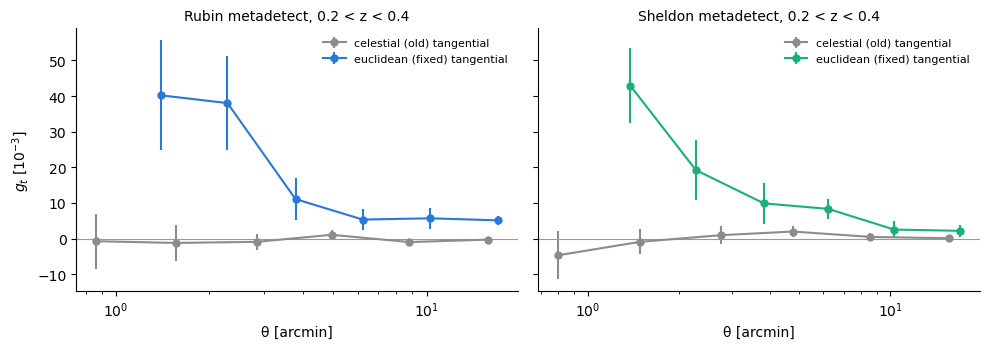

In [23]:
example_bin = "bin_zbin_0_richbin_1"
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, cat in zip(axes, ["rubin", "sheldon"]):
    draw(ax, load_profiles(cat, "gt", "_celestial")[example_bin]["clmm_cluster_ensemble"], "gt", "0.55", "celestial (old)", cross=False)
    draw(ax, load_profiles(cat, "gt")[example_bin]["clmm_cluster_ensemble"], "gt", COLORS[cat], "euclidean (fixed)", shift=1.03, cross=False)
    ax.axhline(0, color="0.6", lw=0.8); ax.set_xscale("log"); ax.set_xlabel(XLABEL["gt"])
    ax.set_title(f"{LABELS[cat]}, 0.2 < z < 0.4", fontsize=10); ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel(r"$g_t$ [$10^{-3}$]")
plt.tight_layout()

## 5.2 Rubin vs Sheldon profiles

Both catalogs use the same clusters, the same cluster bins, the same BPZ photo-z settings and the same profile settings. They differ in the shear measurement, the source selection and the calibration (Rubin: full 2×2 response; Sheldon: $R_{11}$ for both components), so differences between the profiles come from the shear catalogs. Points are offset slightly in radius for clarity; filled = tangential, open = cross (should be zero).

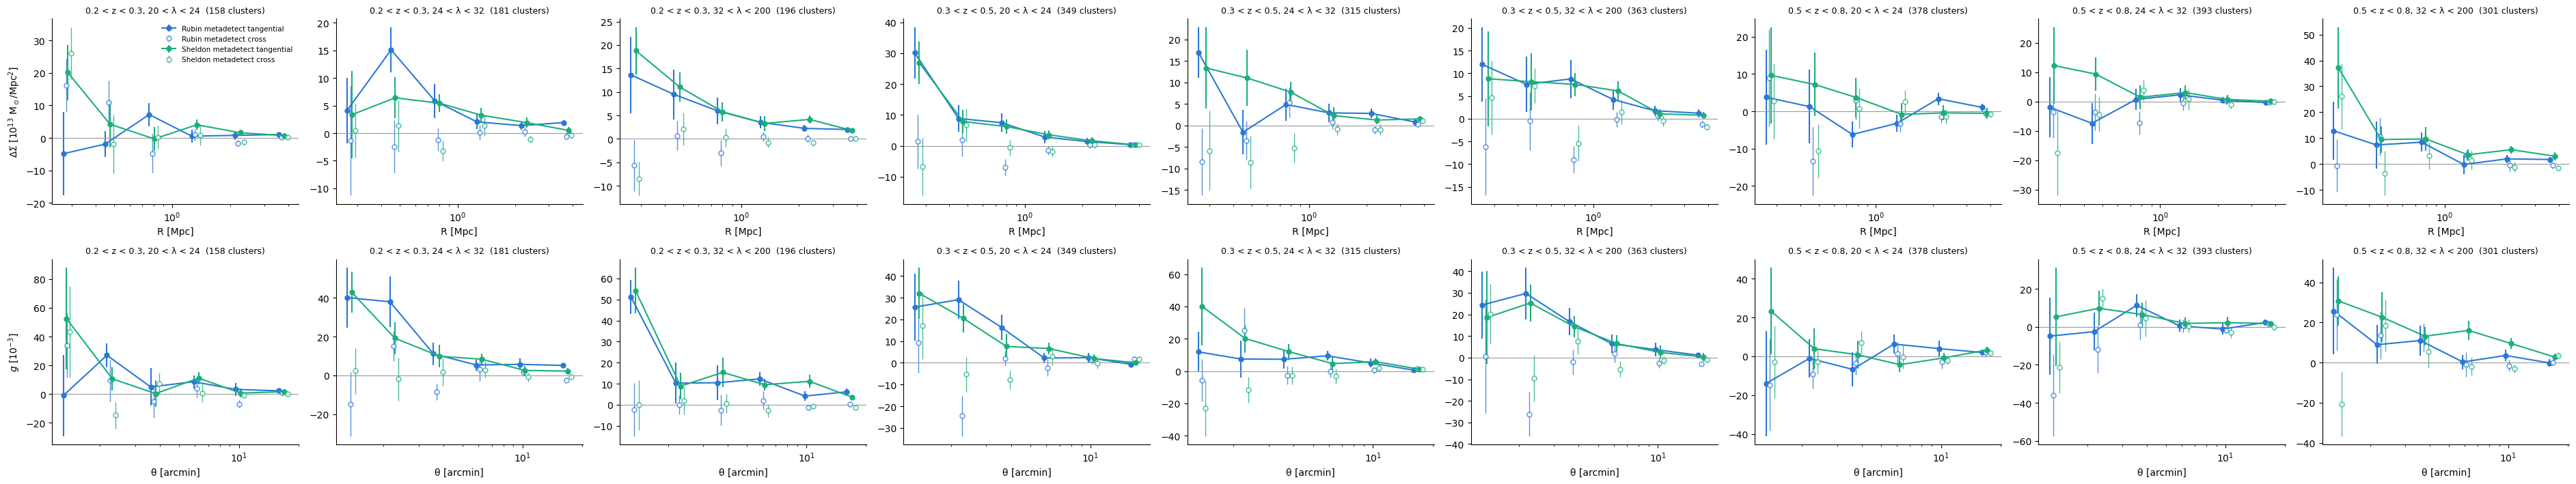

In [24]:
bins = [b for b, e in load_profiles("rubin", "gt").items() if e["n_cl"] > 0]
fig, axes = plt.subplots(2, len(bins), figsize=(4.2 * len(bins), 7.2), squeeze=False)
for row, kind in zip(axes, ["delta_sigma", "gt"]):
    prof = {cat: load_profiles(cat, kind) for cat in ["rubin", "sheldon"]}
    for ax, b in zip(row, bins):
        for cat, shift in [("rubin", 0.97), ("sheldon", 1.03)]:
            draw(ax, prof[cat][b]["clmm_cluster_ensemble"], kind, COLORS[cat], LABELS[cat], shift=shift)
        ax.axhline(0, color="0.6", lw=0.8); ax.set_xscale("log"); ax.set_xlabel(XLABEL[kind])
        ed = prof["rubin"][b]["cluster_bin_edges"]
        ax.set_title(f"{ed['z_min']:.1f} < z < {ed['z_max']:.1f}, {ed['rich_min']:.0f} < λ < {ed['rich_max']:.0f}  ({prof['rubin'][b]['n_cl']} clusters)", fontsize=9)
        ax.spines[["top", "right"]].set_visible(False)
    row[0].set_ylabel(YLABEL[kind])
axes[0][0].legend(frameon=False, fontsize=7.5)
plt.tight_layout()

**What we see** (runs of 2026-10-12):

- After the convention fix, **both catalogs show a clear lensing signal** in the 0.2–0.4 and 0.4–0.6 bins, and their cross components scatter around zero.
- **Sheldon's profiles are less noisy** than Rubin's, as expected from the catalog comparison (`dp2_shear_catalog_comparison.ipynb`, Section 1.4): Sheldon's shapes have lower shape noise ($\sigma_e$ ≈ 0.30 vs 0.36), which more than compensates for having fewer sources.
- **At 0.6 < z < 0.8, Rubin's profile is consistent with zero while Sheldon's shows a signal.** Both use the same clusters and BPZ settings, so this comes from the source samples, for example how many sources lie behind high-redshift clusters.
- **The amplitudes are plausible** (ΔΣ ≈ 5–15 × 10¹³ M$_\odot$/Mpc², i.e. 50–150 M$_\odot$/pc², within 0.5 Mpc). Sheldon's ΔΣ tends to be higher than Rubin's in the inner bins, mostly within the errors. A real difference would point to calibration or to dilution by cluster members: neither run yet includes the response of the photo-z source cut or a boost-factor correction.

## 5.3 Jackknife covariance: k-means vs healpix regions

The error bars and covariance of each stacked profile come from a **jackknife**: the clusters are split into $N$ regions on the sky, the stack is recomputed $N$ times leaving out one region each time, and the scatter of those $N$ profiles gives the covariance. How the sky is split matters:

- **healpix** (CLMM's `compute_jackknife_covariance`, used by `CLClusterEnsembleProfiles`): each region is one healpix pixel at a given `nside`. On DP2's patchy footprint, pixels are filled very unevenly: some hold one cluster, others dozens.
- **k-means** (`compute_kmeans_jackknife_covariance` on the TXPipe branch `cl_kmeans_jackknife`, using `kmeans_radec`): the clusters are grouped into $N$ regions by k-means clustering on the sphere, which gives regions with similar numbers of clusters. The estimator is otherwise identical to CLMM's.

Here we compare the two **for each shear catalog**, using **20 k-means regions** against **healpix `nside` = 8**, the `nside` whose number of occupied pixels is closest to 20 (15–23 per bin; `nside` 4 gives 9–12 and `nside` 16 gives 28–43). Both are computed from the cluster ensembles already saved by the pipeline, so nothing is re-run. The pipeline's own covariance (healpix `nside` = 64, 130–230 regions) is shown as a reference.

The plots use the colours and markers of `CLClusterJackknifeComparisonPlots`: healpix in blue circles, k-means in red squares.

In [25]:
import subprocess
import types
import random
import healpy as hp
import pandas as pd

# k-means jackknife code exactly as committed on the cl_kmeans_jackknife branch, so this
# works whichever TXPipe branch is checked out
src = subprocess.run(["git", "-C", my_txpipe_dir, "show",
                      "cl_kmeans_jackknife:txpipe/extensions/cluster_counts/jk_kmeans.py"],
                     capture_output=True, text=True, check=True).stdout
jk_kmeans = types.ModuleType("jk_kmeans")
exec(src, jk_kmeans.__dict__)

NJK_KMEANS = 20      # k-means regions
NSIDE_JK = 8         # healpix nside with ~20 occupied pixels
SEED = 11            # kmeans_seed default of CLClusterEnsembleProfiles on cl_kmeans_jackknife
CATALOGS = ["rubin", "sheldon"]
KINDS = ["delta_sigma", "gt"]

def region_counts(labels):
    return np.unique(labels, return_counts=True)[1]

jk = {}   # (catalog, kind, bin) -> profile, covariances and regions
for cat in CATALOGS:
    for kind in KINDS:
        for b, e in load_profiles(cat, kind).items():
            ens = e["clmm_cluster_ensemble"]
            if ens is None:
                continue
            r = {"edges": e["cluster_bin_edges"], "n_cl": len(ens.data),
                 "ra": np.array(ens.data["ra"]), "dec": np.array(ens.data["dec"]),
                 "radius": np.array(ens.stacked_data["radius"]),
                 "tan": np.array(ens.stacked_data["tangential_comp"]),
                 "cross": np.array(ens.stacked_data["cross_comp"]),
                 # the pipeline's covariance (healpix nside 64), saved before it is overwritten below
                 "cov": {"healpix 64": (ens.cov["tan_jk"].copy(), ens.cov["cross_jk"].copy())}}
            r["labels"] = {"healpix 64": hp.ang2pix(64, r["ra"], r["dec"], nest=True, lonlat=True)}
            # healpix at nside 8 (CLMM overwrites cov["tan_jk"])
            ens.compute_jackknife_covariance(tan_component="tangential_comp", cross_component="cross_comp", n_side=NSIDE_JK)
            r["cov"][f"healpix {NSIDE_JK}"] = (ens.cov["tan_jk"].copy(), ens.cov["cross_jk"].copy())
            r["labels"][f"healpix {NSIDE_JK}"] = hp.ang2pix(NSIDE_JK, r["ra"], r["dec"], nest=True, lonlat=True)
            # k-means, 20 regions
            jk_kmeans.compute_kmeans_jackknife_covariance(ens, NJK_KMEANS, tan_component="tangential_comp",
                                                          cross_component="cross_comp", seed=SEED)
            r["cov"][f"k-means {NJK_KMEANS}"] = (ens.cov["tan_kmjk"].copy(), ens.cov["cross_kmjk"].copy())
            random.seed(SEED); np.random.seed(SEED)    # same seeding as inside the function, to get its regions
            r["labels"][f"k-means {NJK_KMEANS}"] = jk_kmeans.jk_regions(np.vstack((r["ra"], r["dec"])).T, njk=NJK_KMEANS)[0]
            jk[(cat, kind, b)] = r

HP, KM, REF = f"healpix {NSIDE_JK}", f"k-means {NJK_KMEANS}", "healpix 64"
rows = []
for (cat, kind, b), r in jk.items():
    row = {"catalog": cat, "profile": kind, "z": f"{r['edges']['z_min']:.1f}-{r['edges']['z_max']:.1f}",
           "clusters with sources": r["n_cl"]}
    for m in [HP, KM]:
        n = region_counts(r["labels"][m])
        row[f"{m}: regions"] = n.size
        row[f"{m}: clusters/region"] = f"{n.min()}-{n.max()}"
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))

catalog     profile       z  clusters with sources  healpix 8: regions healpix 8: clusters/region  k-means 20: regions k-means 20: clusters/region
  rubin delta_sigma 0.2-0.4                    318                  22                       1-72                   20                        3-32
  rubin delta_sigma 0.4-0.6                    486                  17                      1-136                   20                        2-45
  rubin delta_sigma 0.6-0.8                    255                  15                       1-84                   20                        2-25
  rubin          gt 0.2-0.4                    333                  22                       1-72                   20                        7-28
  rubin          gt 0.4-0.6                    529                  19                      1-138                   20                        3-48
  rubin          gt 0.6-0.8                    283                  15                       1-88                   20

Only the clusters with sources inside the shear footprint enter the stack (about a third of the clusters in each bin). With ~20 regions, **healpix pixels are very uneven** on DP2's patchy footprint, from a single cluster to several dozen, while **k-means regions hold similar numbers of clusters**.

### **The regions on the sky**

The two splits for the lowest redshift bin of the $g_t$ profile, for each shear catalog. Each colour is one jackknife region.

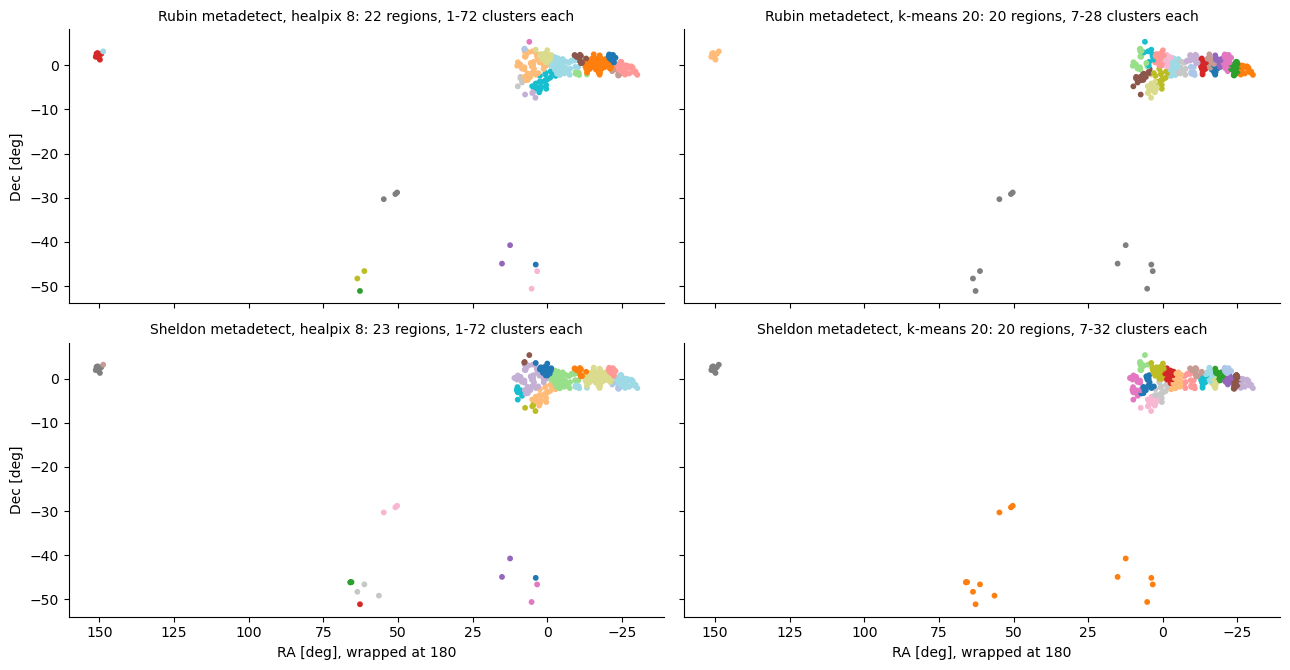

In [26]:
example_bin = "bin_zbin_0_richbin_1"
fig, axes = plt.subplots(len(CATALOGS), 2, figsize=(13, 3.4 * len(CATALOGS)), sharex=True, sharey=True)
for row, cat in zip(axes, CATALOGS):
    r = jk[(cat, "gt", example_bin)]
    ra_w = np.where(r["ra"] > 180, r["ra"] - 360, r["ra"])
    for ax, m in zip(row, [HP, KM]):
        u, inv, n = np.unique(r["labels"][m], return_inverse=True, return_counts=True)
        colour = np.random.default_rng(0).permutation(len(u))
        ax.scatter(ra_w, r["dec"], c=colour[inv], cmap="tab20", s=10)
        ax.set_title(f"{LABELS[cat]}, {m}: {len(u)} regions, {n.min()}-{n.max()} clusters each", fontsize=10)
        ax.spines[["top", "right"]].set_visible(False)
    row[0].set_ylabel("Dec [deg]")
axes[-1][0].invert_xaxis()
for ax in axes[-1]:
    ax.set_xlabel("RA [deg], wrapped at 180")
plt.tight_layout()

### **Error bar against radius**

The simplest comparison: $\sigma(r)$ from the 20 k-means regions overplotted on $\sigma(r)$ from the healpix pixels, for each radial bin. One row per profile type, one column per redshift bin, one figure per shear catalog. The pipeline's healpix-64 errors are shown as a thin grey line for reference. Both axes are logarithmic, so the radial trend (errors shrinking with radius as each annulus contains more sources) and any systematic offset between the methods are easy to see.

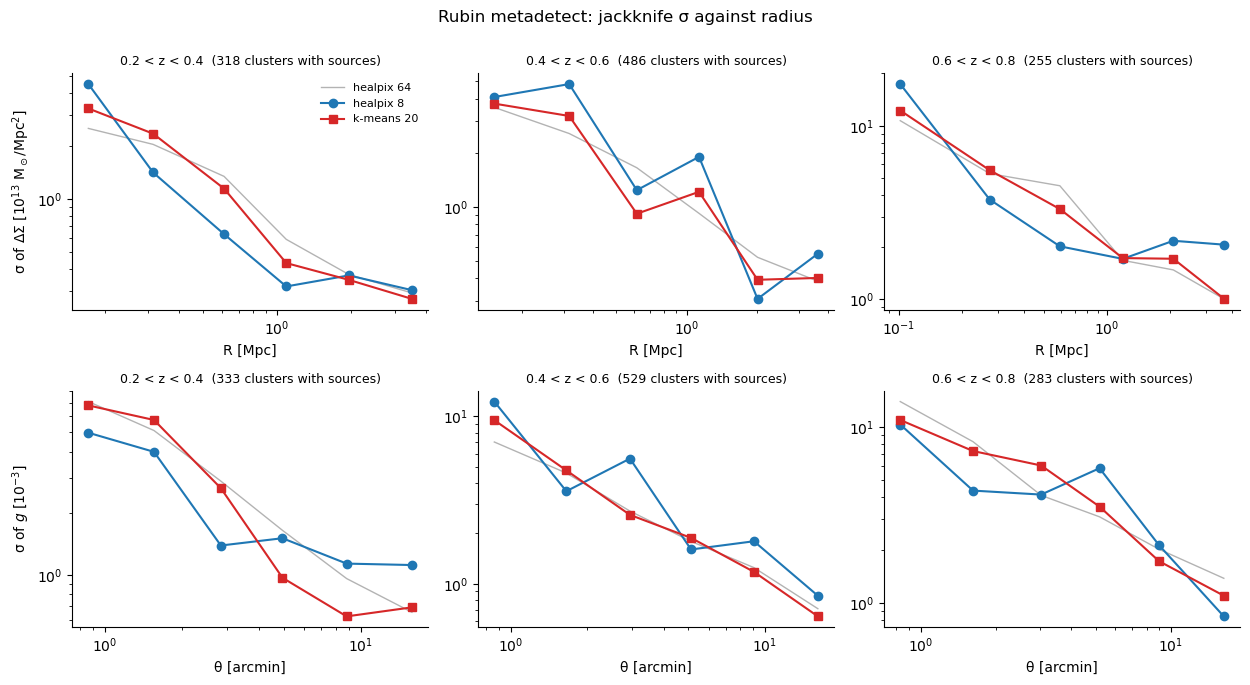

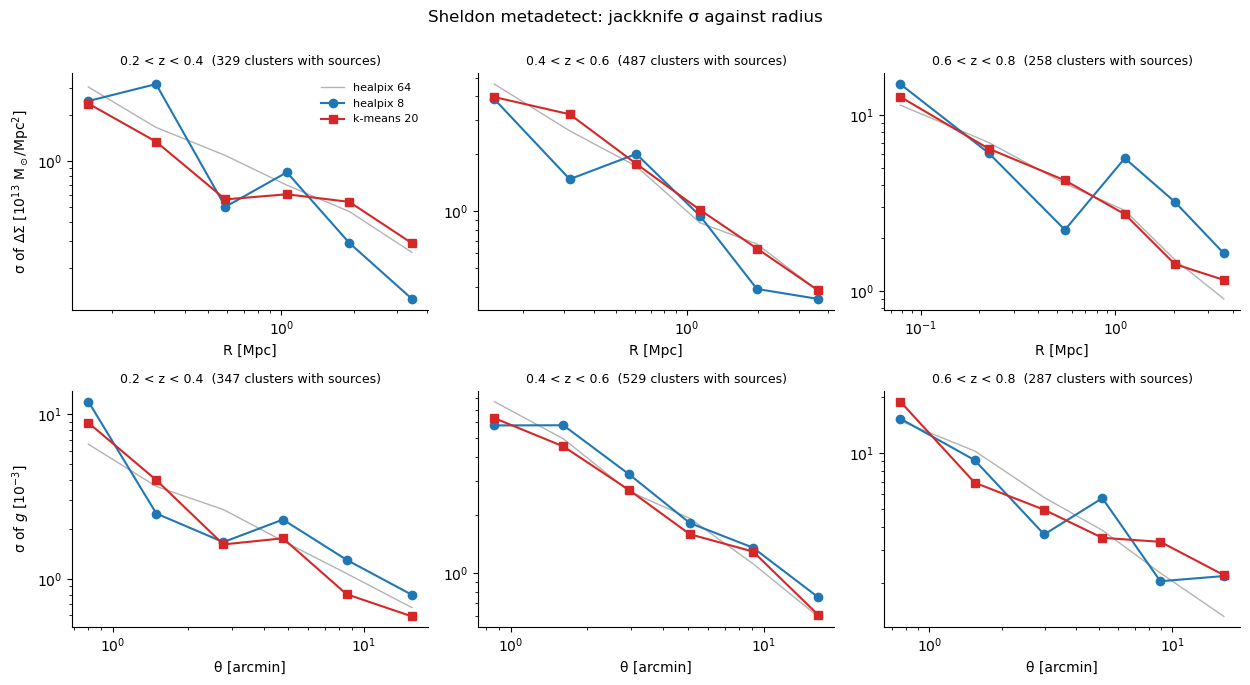

In [27]:
# colours and markers as in CLClusterJackknifeComparisonPlots: healpix C0 circles, k-means C3 squares
STYLE = {HP: dict(color="C0", marker="o"), KM: dict(color="C3", marker="s")}

def sigma(r, m):
    return np.sqrt(np.diag(r["cov"][m][0]))

for cat in CATALOGS:
    bins = [b for (c, k, b) in jk if c == cat and k == "gt"]
    fig, axes = plt.subplots(len(KINDS), len(bins), figsize=(4.2 * len(bins), 3.4 * len(KINDS)), squeeze=False)
    for row, kind in zip(axes, KINDS):
        for ax, b in zip(row, bins):
            r = jk[(cat, kind, b)]
            ax.plot(r["radius"], sigma(r, REF) / SCALE[kind], "-", color="0.7", lw=1, label=REF)
            for m in [HP, KM]:
                ax.plot(r["radius"], sigma(r, m) / SCALE[kind], "-", lw=1.5, ms=6, label=m, **STYLE[m])
            ax.set_xscale("log"); ax.set_yscale("log")
            ax.set_xlabel(XLABEL[kind])
            ed = r["edges"]
            ax.set_title(f"{ed['z_min']:.1f} < z < {ed['z_max']:.1f}  ({r['n_cl']} clusters with sources)", fontsize=9)
            ax.spines[["top", "right"]].set_visible(False)
        row[0].set_ylabel(f"σ of {YLABEL[kind]}")
    axes[0][0].legend(frameon=False, fontsize=8)
    fig.suptitle(f"{LABELS[cat]}: jackknife σ against radius", y=1.0)
    plt.tight_layout()
    plt.show()

### **Error bars, for each shear catalog**

One figure per shear catalog, in the layout of `CLClusterJackknifeComparisonPlots` on `cl_kmeans_jackknife`: each column is a redshift bin; for each profile type the upper panel shows the stacked tangential profile with both sets of error bars, and the lower panel the ratio $\sigma_{\rm k\text{-}means\,20} / \sigma_{\rm healpix\,8}$ at each radius. The grey band marks ±20%.

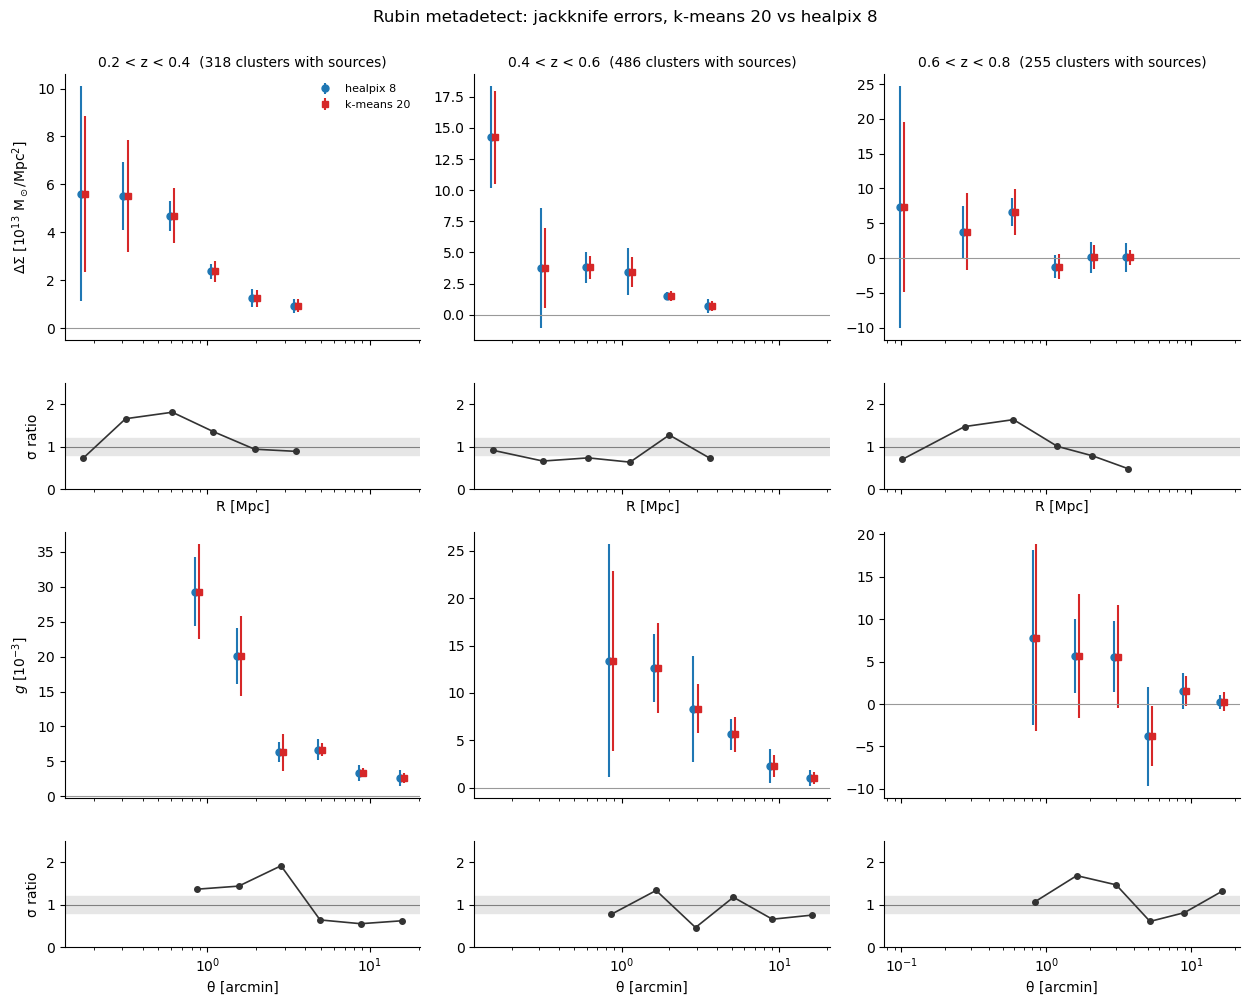

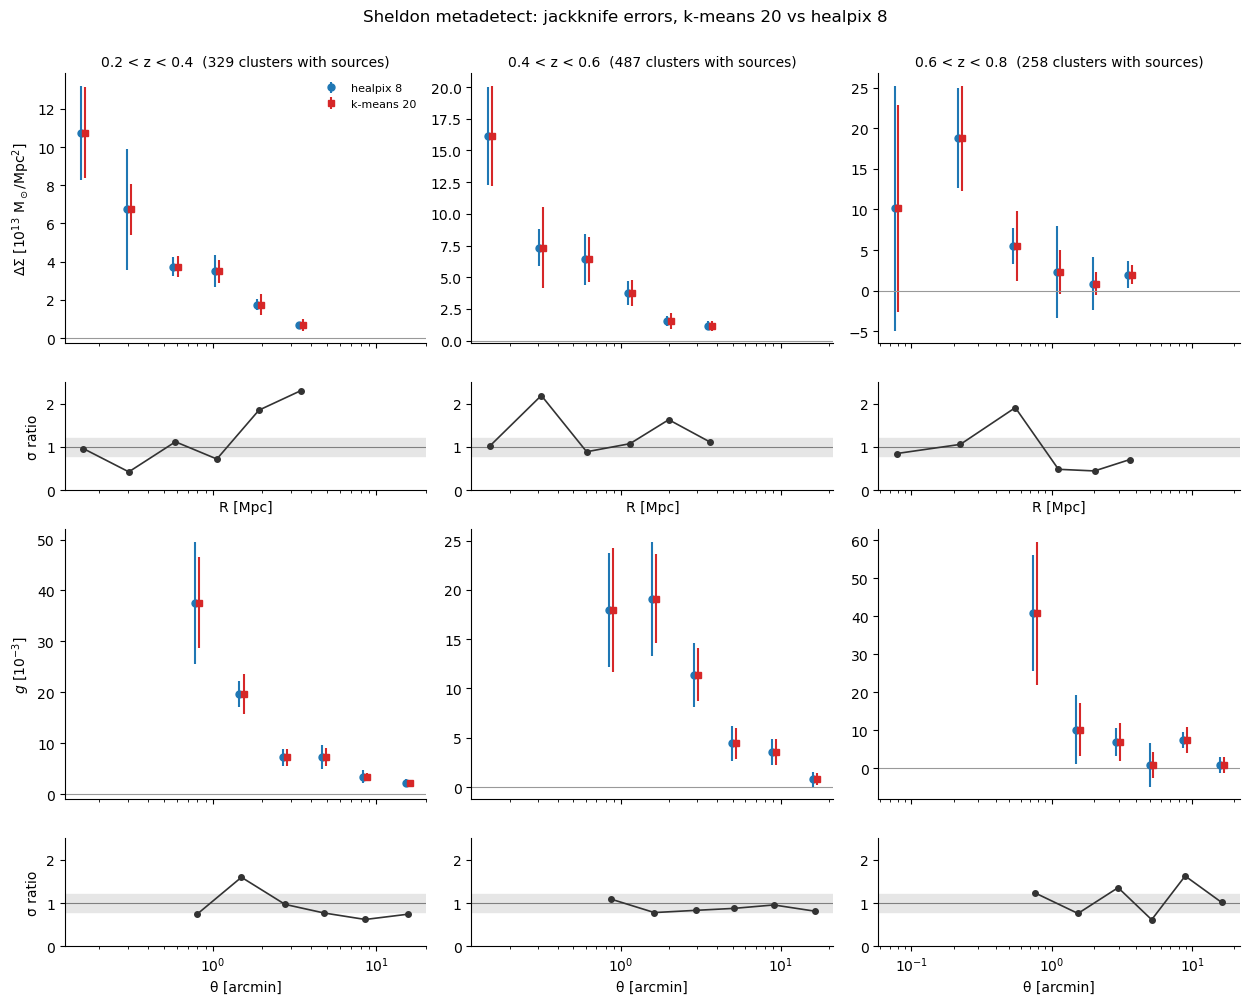

In [28]:
for cat in CATALOGS:
    bins = [b for (c, k, b) in jk if c == cat and k == "gt"]
    fig, axes = plt.subplots(4, len(bins), figsize=(4.2 * len(bins), 10), sharex="col",
                             gridspec_kw={"height_ratios": [3, 1.2, 3, 1.2]}, squeeze=False)
    for col, b in enumerate(bins):
        for k, kind in enumerate(KINDS):
            r = jk[(cat, kind, b)]
            ax, axr = axes[2 * k][col], axes[2 * k + 1][col]
            for m, shift in [(HP, 0.97), (KM, 1.03)]:
                ax.errorbar(r["radius"] * shift, r["tan"] / SCALE[kind], yerr=sigma(r, m) / SCALE[kind],
                            ls="none", ms=5, lw=1.5, label=m, **STYLE[m])
            ax.axhline(0, color="0.6", lw=0.8)
            axr.axhspan(0.8, 1.2, color="0.9")
            axr.axhline(1, color="0.5", lw=0.8)
            axr.plot(r["radius"], sigma(r, KM) / sigma(r, HP), "o-", color="0.2", ms=4, lw=1.2)
            axr.set_ylim(0, 2.5)
            for a in (ax, axr):
                a.set_xscale("log"); a.spines[["top", "right"]].set_visible(False)
            if col == 0:
                ax.set_ylabel(YLABEL[kind]); axr.set_ylabel("σ ratio")
            if k == 0:
                ed = r["edges"]
                ax.set_title(f"{ed['z_min']:.1f} < z < {ed['z_max']:.1f}  ({r['n_cl']} clusters with sources)", fontsize=10)
            axr.set_xlabel(XLABEL[kind])
    axes[0][0].legend(frameon=False, fontsize=8)
    fig.suptitle(f"{LABELS[cat]}: jackknife errors, {KM} vs {HP}", y=1.0)
    plt.tight_layout()
    plt.show()

### **All radii and bins together**

$\sigma_{\rm k\text{-}means\,20}$ against $\sigma_{\rm healpix\,8}$ for every radius and bin, both relative to the pipeline's $\sigma$ (healpix 64) so that ΔΣ and $g_t$ fit on one plot. Points on the diagonal mean the two coarse estimates agree.

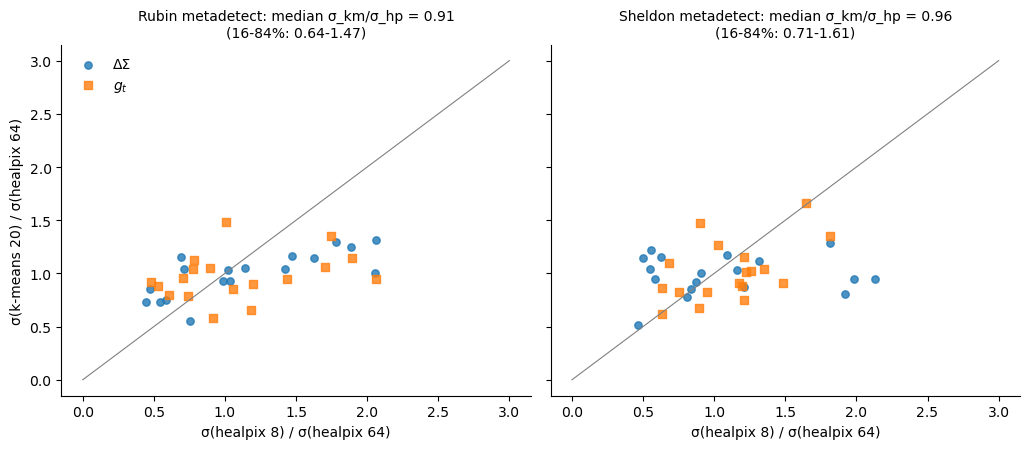

In [29]:
fig, axes = plt.subplots(1, len(CATALOGS), figsize=(5.2 * len(CATALOGS), 4.6), sharex=True, sharey=True)
for ax, cat in zip(axes, CATALOGS):
    for kind, marker in [("delta_sigma", "o"), ("gt", "s")]:
        x = np.concatenate([sigma(r, HP) / sigma(r, REF) for (c, k, b), r in jk.items() if c == cat and k == kind])
        y = np.concatenate([sigma(r, KM) / sigma(r, REF) for (c, k, b), r in jk.items() if c == cat and k == kind])
        ax.scatter(x, y, marker=marker, s=28, alpha=0.8, label={"delta_sigma": "ΔΣ", "gt": "$g_t$"}[kind])
    ratio = np.concatenate([sigma(r, KM) / sigma(r, HP) for (c, k, b), r in jk.items() if c == cat])
    ax.plot([0, 3], [0, 3], color="0.5", lw=0.8)
    ax.set_title(f"{LABELS[cat]}: median σ_km/σ_hp = {np.median(ratio):.2f}\n(16-84%: {np.percentile(ratio, 16):.2f}-{np.percentile(ratio, 84):.2f})", fontsize=10)
    ax.set_xlabel(f"σ({HP}) / σ(healpix 64)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel(f"σ({KM}) / σ(healpix 64)")
axes[0].legend(frameon=False)
plt.tight_layout()

**What we see** (runs of 2026-10-12, seed 11):

- **Regions.** With ~20 regions, healpix pixels on DP2's footprint are very uneven (from 1 cluster up to ~140 in a single pixel), while k-means regions are much more even (about 2–50 clusters each). k-means also groups the sparse far-southern clusters (Dec ≈ −30° to −50°) into one region.
- **Error bars.** For both catalogs there is no systematic offset between the two: the median $\sigma_{\rm k\text{-}means\,20}/\sigma_{\rm healpix\,8}$ is close to 1 (0.91 for Rubin, 0.96 for Sheldon), and both follow the same radial trend. But the ratio scatters widely from point to point (roughly 0.4–2.3), because both estimates are noisy with only ~20 jackknife samples. Compared with the pipeline's fine covariance (healpix 64), the k-means errors stay within about 0.5–1.5×, while the healpix-8 errors range over 0.45–2.1×, so of the two coarse estimates k-means is the less noisy. Changing the k-means seed alone changes $\sigma$ by ~11% (median) at 20 regions.
- **Conclusion.** If a coarse jackknife is needed on DP2 (to capture correlations on scales larger than a single cluster), **k-means regions are the better choice than healpix pixels** at the same number of regions. With the current number of clusters, the errors are dominated by shape noise: a broader test (healpix nside 8–64, k-means 20–80 regions) gave the same per-point errors as the pipeline's nside 64 to within a few percent once there were more than ~40 regions.
- **Small CLMM detail.** CLMM's jackknife formula, which the k-means code copies, equals the textbook jackknife variance times $(N-1)/N$, i.e. $\sigma$ is ~2.5% low for 20 regions (negligible for ~190).

In [33]:
C = jk[("rubin", "gt", "bin_zbin_0_richbin_1")]["cov"][KM][0]
np.linalg.matrix_rank(C) == C.shape[0], np.linalg.cond(C)

(np.True_, np.float64(362.6111264053305))

___

# 6 - Next

- Investigate the 0.6 < z < 0.8 difference between Rubin and Sheldon (sources behind high-redshift clusters).
- Calibration of the background selection (the photo-z cut's shear response) and boost factors, before comparing amplitudes.
- Add AnaCal once TXPipe's AnaCal branch is compatible with `Metadetect_aliasing`.

In [1]:
def plot_binning(clusters_in, bins_out, zedge, richedge):
    """Plot the input clusters, the bin edges, and the clusters in each output bin."""
    # plot data from input catalog
    plt.semilogy(clusters_in['redshift'], clusters_in['richness'], 'k.', alpha=1)
    plt.xlabel('redshift')
    plt.ylabel('richness')

    # plot bin limits as defined in the config file
    for z in zedge:
        plt.axvline(z, linestyle='dashed', color='black')
    for r in richedge:
        plt.axhline(r, linestyle='dotted', color='black')

    # overplot data from output file to make sure the bins are ordered correctly
    markers = ['s', 'o', 'D', 'P', '^']
    for i in range(len(zedge) - 1):
        for j in range(len(richedge) - 1):
            name = f'bin_zbin_{i}_richbin_{j}'
            plt.scatter(bins_out[name]['redshift'], bins_out[name]['richness'],
                        marker=markers[j % len(markers)], label=name)
    plt.legend(fontsize='x-small', bbox_to_anchor=(1.02, 1), loc='upper left')

## Small test todo: member contamination, can use Clevar

- Need to consider how we compare anacal vs metadetect shears, and also rubin and sheldon ones
- Check Abell360 project, they did something similar already
- Will also want to also probe more in 1 halo regime when testing contamination